In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns

In [2]:
import tensorflow as tf
from tensorflow.keras import datasets
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

tensorflow를 이용해서 합성곱 신경망(Convolution Neural Network, CNN) 모델 구현에 필요한 라이브러리들을 import 한다.

In [3]:
from tensorflow.keras.layers import Conv2D # 2차원 합성곱 신경망 신경망 레이어를 생성한다.
from tensorflow.keras.layers import MaxPool2D # 신경망에 추가할 맥스 풀링 레이어를 생성한다.
from tensorflow.keras.layers import Flatten # 신경망의 최종 출력 레이어를 벡터 형태(1차원)로 만든다.
from tensorflow.keras.layers import Dropout # 신경망에 추가할 드롭다운 레이어를 생성한다.

# 합성곱 신경망(Convolution Neural Network, CNN)

합성곱 신경망은 흔히 CNN이라고 부른 합성곱 연산을 사용하는 신경망으로 실제 여러 분야에서 사용되는 방법으로 특히 `이미지 분류 작업`에서 좋은 성능을 보여준다.  
시각적 이미지나 영상 등의 데이터를 분석하고 처리하는 데 특화된 대표적인 딥러닝 알고리즘으로 `인간의 뇌가 시각 정보를 받아들이는 방식을 모방`해서 만들어졌다.

합성곱 연산은 아래와 같은 연산을 의미한다.

$$y(i) = (x \times w)(i) = \sum_{k=1}^{\infty} x(i - k)w(k)$$

컴퓨터 비전에서 많이 사용되는 딥러닝 모델인 CNN의 장점은 다층 퍼셉트론과 비교하면 쉽게 알 수 있다.

다층 퍼셉트론의 첫 번째 단점은 `이미지의 고유한 생김새를 사용할 수 없다는 것`이다.
다층 퍼셉트론의 경우 2차원 데이터를 입력할 수 없으므로 이미지 데이터를 입력하기위해서 2차원 평면에 있는 숫자 이미지를 `1차원 배열로 변환`해야 한다.  
1차원 배열로 변환된 이미지 데이터는 원래 숫자 이미지를 떠올리기 쉽지않다. 1차원으로 변환된 이미지 데이터를 입력받은 다층 퍼셉트론의 경우, 이미지가 2차원 평면에서 가지고 있던 `모양(지역) 정보를 잃어버린 채 학습`을 시작한다.

두 번째 단점은 다층 퍼셉트론은 픽셀 하나 하나의 `변화에 상당히 민감`하다는 것이다.
이미지의 생김새 정보를 사용할 수 없는 다층 퍼셉트론은 가지고 있는 정보가 픽셀 정보밖에 없기 때문에 한 두 개 차이가 모델 예측에 큰 영향을 끼치게 된다.

세 번째 단점은 다층 퍼셉트론은 픽셀 한 두 개의 정보에도 민감하게 반응하기때문에 `상당히 많은 변수를 모델안에 가지고 있다`는 것이다. 이로인해 모델의 크기를 크게 만들고, 학습 시간이 오래 걸리며, 자칫 잘못하면 과적합된 모델이 되기쉽다.

## 이미지의 생김새 정보 획득하기

<img src="./CNN1.png" width="1000" align="left" />

두 개의 비슷한 생김새의 숫자 2가 있을때 전체적인 생김새는 달라도 머리와 꼬리 부분이 있고 머리와 꼬리를 이어주는 대각선이 있다면 단번에 숫자 2임을 판별할 수 있다.

## CNN은 어떻게 이미지의 생김사 특징을 찾아내는가?

<img src="./CNN2.png" width="1000" align="left" />

위의 그림에서 `필터 또는 커널`이라고 불리는 반투명한 네모 상자가 이미지 `왼쪽 최상단`에서 일정한 간격으로 이동하면서 `오른쪽 최하단`까지 이동한다. 이처럼 필터를 이동하는 기법을 `스트라이드(stride)`라고 한다.

스트라이드는 한 번 합성곱 연산을 한 후 다음 계산 영역을 선택할 때 얼마나 이동할지 `간격`을 정하는 것이다.

필터는 `이미지의 특징을 추출`하기 위한 네모 상자이고 이 필터와 겹치는 이미지 부분을 수용 영역이라 부른다.

아래 그림에서 대각선 필터는 숫자 2로 부터 두 곳의 대각선 특징을 발견한다. 그러나 숫자 1에서는 대각선 특징을 발견하지 못한다.

<img src="./CNN3.png" width="700" align="left" />

모든 딥러닝 모델이 그렇듯이 CNN 모델 역시 수학적인 모델이다. 필터가 어떻게 특징을 추출하는지 알아보자.

MNIST 숫자 데이터는 흑백 이미지로 각 픽셀은 0부터 255 사이의 값 중 하나를 가지고 있다. 픽셀 안의 숫자 0은 흰색을 의미하고 255는 검은색을 의미한다. 그리고 그 사이의 숫자는 검은색과 흰색 사이의 어떤 색(회색)을 의미한다.  
만약 이미지 안에 오직 흰색과 검은색만 존재한다면 아래 그림과 같이 0과 255로만 구성되어 있을 것이다.

<img src="./CNN4.png" width="900" align="left" />

위의 그림에서 알 수 있듯이 필터 안에는 특정한 숫자가 들어있고 필터와 이미지가 겹치는 부분마다 곱셈이 이루어지고 필터에 4개의 픽셀이 있다면 4개 영역이 곱해지고 곱해진 값은 최종적으로 더해진다.  
최종값이 크다는 의미는 필터와 겹쳐진 부분이 많다는 의미이며 반대로 최종값이 작을 경우 겹쳐지는 부분이 적었다라고 해석할 수 있다.

CNN 모델안에서 각 특성의 개수만큼 필터가 필요하다.  
보통 `전반부에 존재하는 필터`는 직선, 곡선 같은 `기초적인 특성`을 구별하기 위해 존재하고 `후반부에 존재하는 필터`는 동그라미, 세모 같은 좀 더 `고차원의 특징`을 구분하기 위해 존재한다.  
필터를 사용해서 `모든 특징`을 찾아낸 후, 이 특징들은 `다중 퍼셉트론의 입력`값으로 들어가서 필터로 부터 구별된 특징을 기반으로 숫자 `분류`를 진행한다.

<img src="./CNN5.png" width="700" align="left" />

`필터`를 스트라이드를 통해 얻어진 행렬을 `피쳐 맵(feature map)`이라고 한다.  
피쳐 맵을 `활성화 함수`에 넣어 구현한 행렬을 `액티베이션 맵(activation map)`이라고 한다.

맥스 풀링(max pooling)은 지정된 영역에서 `가장 큰 수치를 선택`하고 나머지는 버린다.

아래 그림은 2 * 2 필터에 스트라이드를 적용한 피쳐 맵에 맥스 풀링을 적용한 예이다.  
피쳐 맵의 크기가 줄어듬으로써 얻는 장점은 계산에 사용하는 파라미터의 개수가 줄어들어 계산 속도가 빨라지고 파라미터를 줄임으로써 모델의 분산을 줄이고 그에 따라 과적합 가능성을 줄여준다.

<img src="./CNN6.png" width="400" align="left" />

제로 패딩(zero padding)은 `0으로` 입력 행렬의 테두리를 `감싸주는 기술`이다.

스트라이드를 통해 입력된 행렬보다 `작아진 행렬이 출력`되고 작아진 만큼 `정보 손실이 발생`되므로 제로 패딩을 통해 입력 행렬의 크기를 크게 함으로써 `스트라이드 이후에도 이미지 크기를 동일하게 유지`할 수 있다.

<img src="./CNN7.png" width="500" align="left" />

제로 패딩으로 인해 스트라이드 할 공간이 더 많아졌다. 만약 필터 크기가 3 * 3이고 스트라이드를 1픽셀씩 할 경우 피쳐 맵은 5 * 5로 제로 패딩을 하기 전의 입력과 동일한 크기로 출력될것이다.

## CNN 알고리즘을 사용하는 손글씨 숫자 이미지 분류 작업 흐름도

<img src="./CNN8.png" width="1000" align="left" />

# CNN 알고리즘으로 분류할 MNIST 손글씨 숫자 데이터를 불러와서 전처리한다.

## keras가 제공하는 MNIST 손글씨 숫자 데이터셋을 불러온다.

In [4]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


## 원본 데이터 시각화

[5 0 4 1 9 2 1 3 1 4]


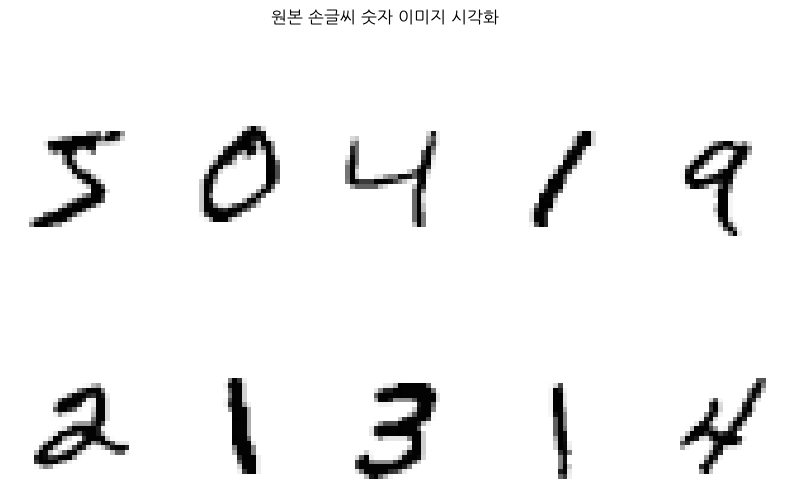

In [11]:
print(y_train[:10])
plt.figure(figsize=[10, 6])
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='Grays')
    plt.axis('off')
plt.suptitle('원본 손글씨 숫자 이미지 시각화')
plt.show()

레이블 종류 확인 => 분류 문제인지 회귀 문제인지 파악할 수 있고 분류 문제라면 몇 개의 클래스로 구분되는지 알 수 있다.

In [14]:
print(set(y_train))
n_class = len(set(y_train))
print(n_class)

{np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9)}
10
